# EN3160 — Assignment 3: Neural Networks

### Hiruna Kariyawasam (230318M)
### [https://github.com/HirunaK/230318M-A03-Neural-Networks](https://github.com/HirunaK/230318M-A03-Neural-Networks)

## Setup

In [1]:
import os
import copy
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
Device: cuda


## Question 1

In [ ]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 128
train_set = datasets.CIFAR10(root="./data", train=True, download=True, transform=cifar_transform)
test_set = datasets.CIFAR10(root="./data", train=False, download=True, transform=cifar_transform)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=2,
                         pin_memory=torch.cuda.is_available())

classes_cifar = train_set.classes
Din, HIDDEN, K = 3 * 32 * 32, 100, 10
print("Classes:", classes_cifar)
print("Training samples:", len(train_set), "| Test samples:", len(test_set))

100.0%


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training samples: 50000 | Test samples: 10000


In [ ]:
g = torch.Generator().manual_seed(SEED)
W1 = (torch.randn(Din, HIDDEN, generator=g) * np.sqrt(1.0 / Din)).to(device)
b1 = torch.zeros(HIDDEN, device=device)
W2 = (torch.randn(HIDDEN, K, generator=g) * np.sqrt(1.0 / HIDDEN)).to(device)
b2 = torch.zeros(K, device=device)

epochs_q1 = 10
learning_rate = 0.05
lr_decay = 0.9
train_loss_history_q1 = []
train_acc_history_q1 = []
test_acc_history_q1 = []

def evaluate_manual(loader):
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device).view(images.shape[0], -1)
            labels = labels.to(device)
            hidden = torch.sigmoid(images @ W1 + b1)
            logits = hidden @ W2 + b2
            loss = F.cross_entropy(logits, labels, reduction="sum")
            loss_sum += loss.item()
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, 100.0 * correct / total

for epoch in range(epochs_q1):
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        X = images.to(device).view(images.shape[0], -1)
        y = labels.to(device)
        N = X.shape[0]

        A1 = X @ W1 + b1
        H = torch.sigmoid(A1)
        logits = H @ W2 + b2
        loss = F.cross_entropy(logits, y)

        probs = torch.softmax(logits, dim=1)
        probs[torch.arange(N, device=device), y] -= 1.0
        dZ2 = probs / N
        dW2 = H.T @ dZ2
        db2 = dZ2.sum(dim=0)

        dH = dZ2 @ W2.T
        dA1 = dH * H * (1.0 - H)
        dW1 = X.T @ dA1
        db1 = dA1.sum(dim=0)

        with torch.no_grad():
            W1 -= learning_rate * dW1
            b1 -= learning_rate * db1
            W2 -= learning_rate * dW2
            b2 -= learning_rate * db2

        running_loss += loss.item() * N
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += N

    train_loss_history_q1.append(running_loss / total)
    train_acc_history_q1.append(100.0 * correct / total)
    _, test_acc = evaluate_manual(test_loader)
    test_acc_history_q1.append(test_acc)
    print(f"Epoch {epoch+1:02d}/{epochs_q1} | loss={train_loss_history_q1[-1]:.4f} "
          f"| train acc={train_acc_history_q1[-1]:.2f}% | test acc={test_acc:.2f}%")
    learning_rate *= lr_decay

final_train_loss_q1, final_train_acc_q1 = evaluate_manual(train_loader)
final_test_loss_q1, final_test_acc_q1 = evaluate_manual(test_loader)
print(f"\nFinal training accuracy: {final_train_acc_q1:.2f}%")
print(f"Final test accuracy:     {final_test_acc_q1:.2f}%")

Epoch 01/10 | loss=1.9389 | train acc=33.34% | test acc=36.83%
Epoch 02/10 | loss=1.7946 | train acc=38.08% | test acc=38.70%
Epoch 03/10 | loss=1.7503 | train acc=39.54% | test acc=39.90%
Epoch 04/10 | loss=1.7228 | train acc=40.60% | test acc=40.75%
Epoch 05/10 | loss=1.7034 | train acc=41.17% | test acc=41.19%
Epoch 06/10 | loss=1.6878 | train acc=41.85% | test acc=41.59%
Epoch 07/10 | loss=1.6742 | train acc=42.45% | test acc=41.88%
Epoch 08/10 | loss=1.6635 | train acc=42.82% | test acc=42.16%
Epoch 09/10 | loss=1.6544 | train acc=43.05% | test acc=42.56%
Epoch 10/10 | loss=1.6463 | train acc=43.36% | test acc=42.66%

Final training accuracy: 43.57%
Final test accuracy:     42.66%


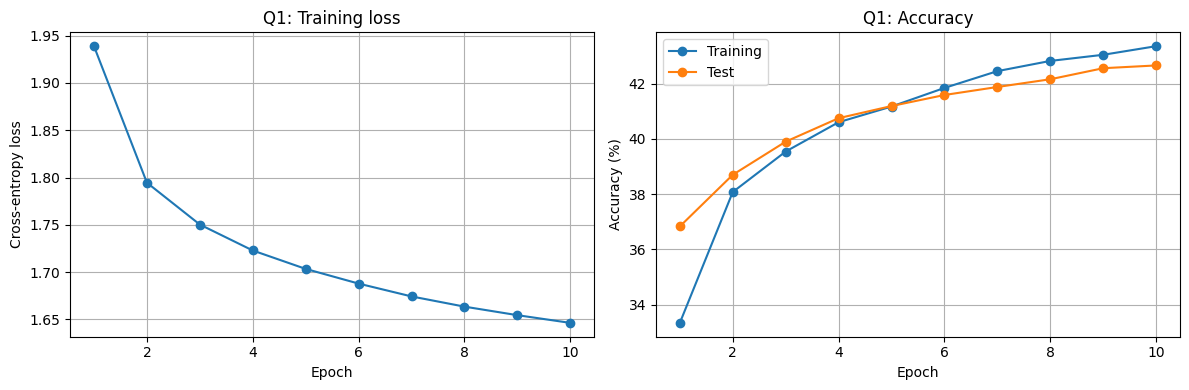

In [4]:
epochs = np.arange(1, epochs_q1 + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, train_loss_history_q1, marker="o")
ax[0].set(title="Q1: Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
ax[0].grid(True)
ax[1].plot(epochs, train_acc_history_q1, marker="o", label="Training")
ax[1].plot(epochs, test_acc_history_q1, marker="o", label="Test")
ax[1].set(title="Q1: Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()

### Results and Discussion

After 10 epochs, the network achieved a training accuracy of **43.57%** and a test accuracy of **42.66%**. The difference between these values gives an idea of how well the model generalizes to unseen data.

## Question 2

In [5]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
mnist_train = datasets.MNIST("./data", train=True, download=True, transform=mnist_transform)
mnist_test = datasets.MNIST("./data", train=False, download=True, transform=mnist_transform)

mnist_batch_size = 128
mnist_train_loader = DataLoader(mnist_train, batch_size=mnist_batch_size, shuffle=True,
                                num_workers=2, pin_memory=torch.cuda.is_available())
mnist_test_loader = DataLoader(mnist_test, batch_size=mnist_batch_size, shuffle=False,
                               num_workers=2, pin_memory=torch.cuda.is_available())

100.0%
100.0%
100.0%
100.0%


### 2(a) LeNet-5

In [ ]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)     
        self.pool1 = nn.AvgPool2d(2)                    
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)    
        self.pool2 = nn.AvgPool2d(2)                  
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.pool1(x)
        x = torch.tanh(self.conv2(x))
        x = self.pool2(x)
        x = torch.flatten(x, 1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)

### 2(b) Small CNN

In [7]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 28 -> 14

            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 14 -> 7

            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Dropout2d(dropout)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [8]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

def train_mnist_model(model, name, epochs=10, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    start = time.time()
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, mnist_train_loader, criterion, optimizer)
        te_loss, te_acc = run_epoch(model, mnist_test_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["test_loss"].append(te_loss)
        history["train_acc"].append(tr_acc)
        history["test_acc"].append(te_acc)
        print(f"{name} | Epoch {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f}, acc {tr_acc:.2f}% | "
              f"test loss {te_loss:.4f}, acc {te_acc:.2f}%")
    print(f"{name} training time: {(time.time()-start)/60:.1f} min")
    return model, history

lenet, lenet_history = train_mnist_model(LeNet5(), "LeNet-5", epochs=10)
small_cnn, cnn_history = train_mnist_model(SmallCNN(), "Small CNN", epochs=10)

LeNet-5 | Epoch 01/10 | train loss 0.3405, acc 90.53% | test loss 0.1093, acc 96.80%
LeNet-5 | Epoch 02/10 | train loss 0.0868, acc 97.36% | test loss 0.0598, acc 98.10%
LeNet-5 | Epoch 03/10 | train loss 0.0585, acc 98.21% | test loss 0.0520, acc 98.44%
LeNet-5 | Epoch 04/10 | train loss 0.0453, acc 98.55% | test loss 0.0382, acc 98.69%
LeNet-5 | Epoch 05/10 | train loss 0.0368, acc 98.86% | test loss 0.0489, acc 98.40%
LeNet-5 | Epoch 06/10 | train loss 0.0307, acc 99.06% | test loss 0.0322, acc 98.92%
LeNet-5 | Epoch 07/10 | train loss 0.0262, acc 99.16% | test loss 0.0349, acc 98.92%
LeNet-5 | Epoch 08/10 | train loss 0.0222, acc 99.33% | test loss 0.0278, acc 99.12%
LeNet-5 | Epoch 09/10 | train loss 0.0192, acc 99.41% | test loss 0.0323, acc 98.96%
LeNet-5 | Epoch 10/10 | train loss 0.0165, acc 99.51% | test loss 0.0339, acc 98.92%
LeNet-5 training time: 1.8 min
Small CNN | Epoch 01/10 | train loss 0.1245, acc 96.16% | test loss 0.0447, acc 98.59%
Small CNN | Epoch 02/10 | train 

### 2(c) Plots and Confusion Matrices

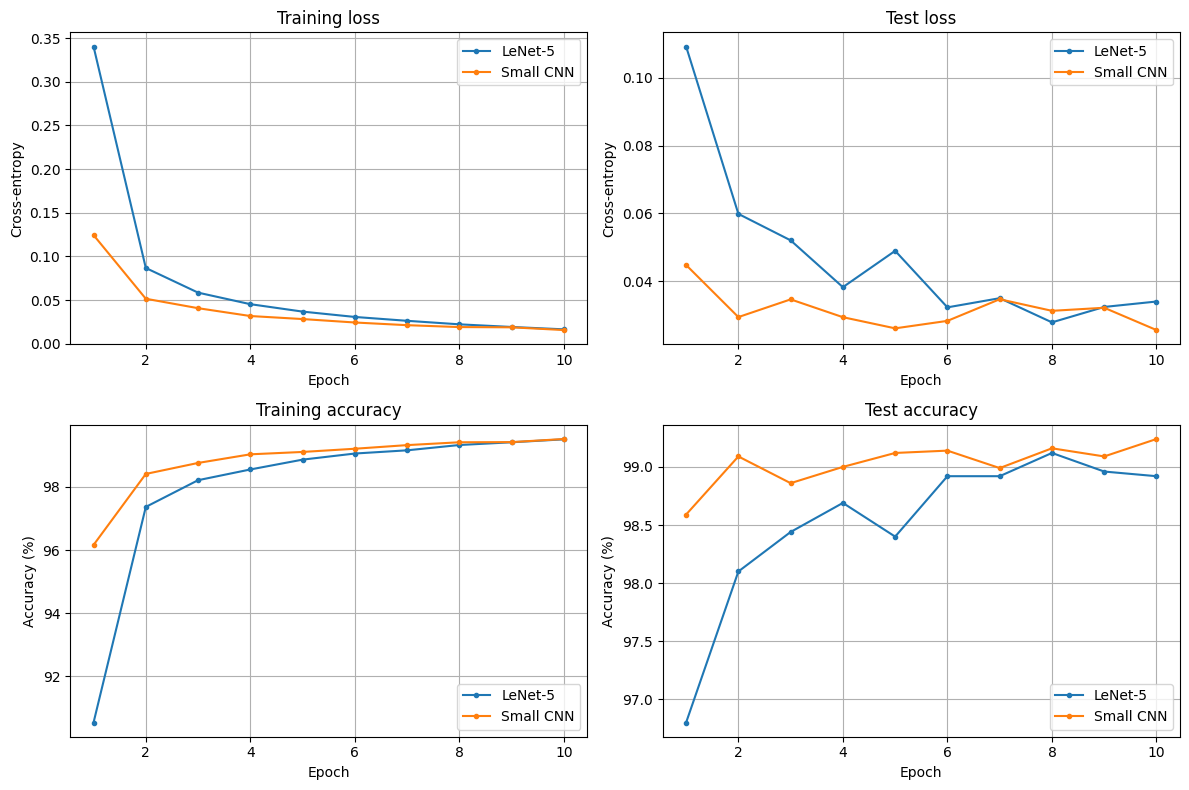

In [9]:
def plot_history(histories):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for name, h in histories.items():
        e = np.arange(1, len(h["train_loss"]) + 1)
        axes[0, 0].plot(e, h["train_loss"], marker=".", label=name)
        axes[0, 1].plot(e, h["test_loss"], marker=".", label=name)
        axes[1, 0].plot(e, h["train_acc"], marker=".", label=name)
        axes[1, 1].plot(e, h["test_acc"], marker=".", label=name)
    axes[0, 0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy")
    axes[0, 1].set(title="Test loss", xlabel="Epoch", ylabel="Cross-entropy")
    axes[1, 0].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    axes[1, 1].set(title="Test accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    for a in axes.flat:
        a.grid(True)
        a.legend()
    plt.tight_layout()
    plt.show()

plot_history({"LeNet-5": lenet_history, "Small CNN": cnn_history})

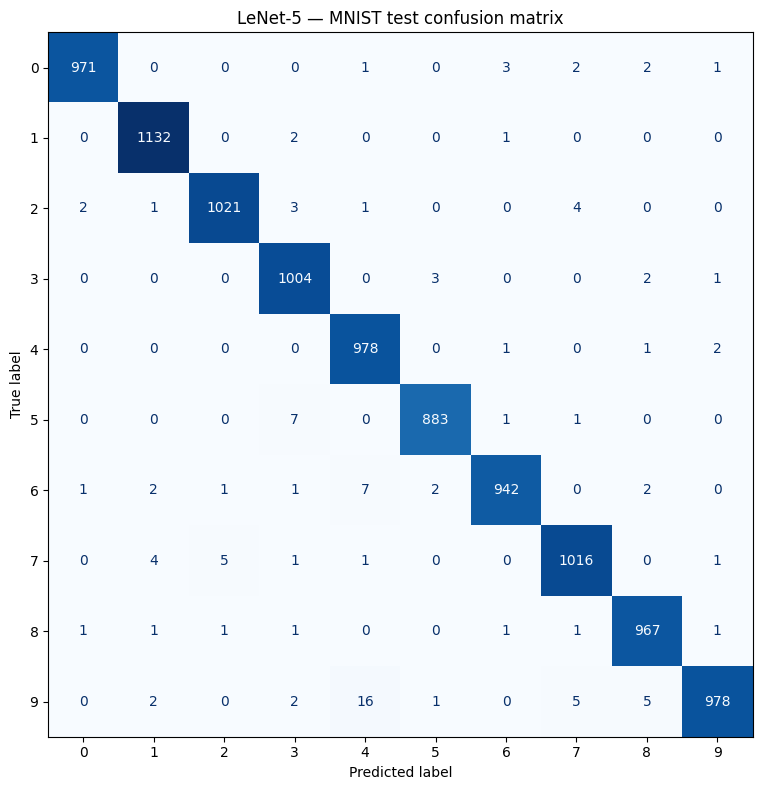

              precision    recall  f1-score   support

           0     0.9959    0.9908    0.9934       980
           1     0.9912    0.9974    0.9943      1135
           2     0.9932    0.9893    0.9913      1032
           3     0.9833    0.9941    0.9887      1010
           4     0.9741    0.9959    0.9849       982
           5     0.9933    0.9899    0.9916       892
           6     0.9926    0.9833    0.9879       958
           7     0.9874    0.9883    0.9878      1028
           8     0.9877    0.9928    0.9903       974
           9     0.9939    0.9693    0.9814      1009

    accuracy                         0.9892     10000
   macro avg     0.9893    0.9891    0.9892     10000
weighted avg     0.9893    0.9892    0.9892     10000



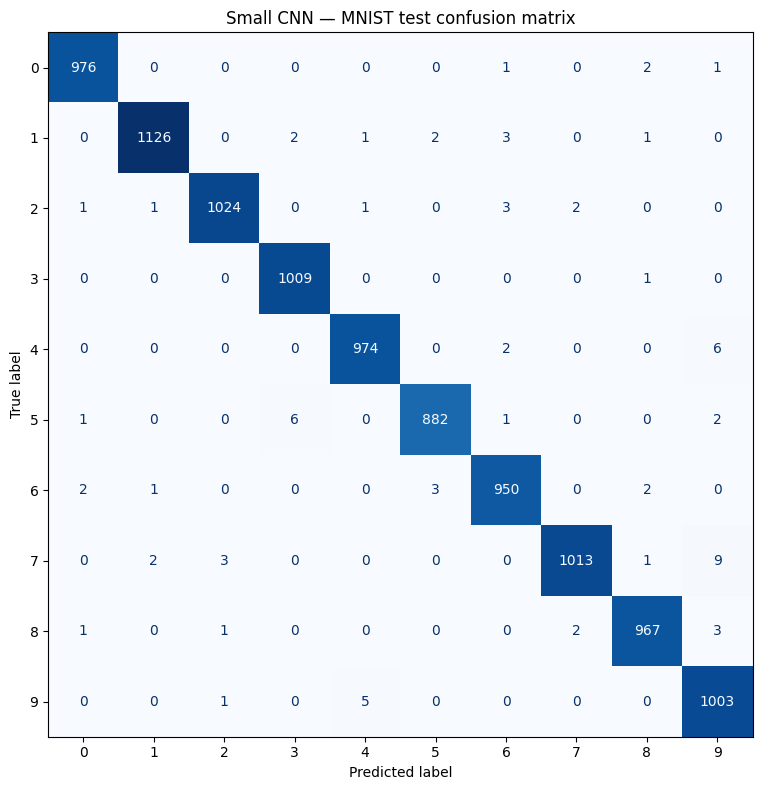

              precision    recall  f1-score   support

           0     0.9949    0.9959    0.9954       980
           1     0.9965    0.9921    0.9943      1135
           2     0.9951    0.9922    0.9937      1032
           3     0.9921    0.9990    0.9956      1010
           4     0.9929    0.9919    0.9924       982
           5     0.9944    0.9888    0.9916       892
           6     0.9896    0.9916    0.9906       958
           7     0.9961    0.9854    0.9907      1028
           8     0.9928    0.9928    0.9928       974
           9     0.9795    0.9941    0.9867      1009

    accuracy                         0.9924     10000
   macro avg     0.9924    0.9924    0.9924     10000
weighted avg     0.9924    0.9924    0.9924     10000



In [10]:
def collect_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            y_pred.extend(logits.argmax(1).cpu().numpy())
            y_true.extend(labels.numpy())
    return np.asarray(y_true), np.asarray(y_pred)

def show_confusion(model, title):
    y_true, y_pred = collect_predictions(model, mnist_test_loader)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    disp = ConfusionMatrixDisplay(cm, display_labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(8, 8))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    return y_true, y_pred, cm

lenet_true, lenet_pred, lenet_cm = show_confusion(lenet, "LeNet-5 — MNIST test confusion matrix")
cnn_true, cnn_pred, cnn_cm = show_confusion(small_cnn, "Small CNN — MNIST test confusion matrix")

In [ ]:
import pandas as pd
comparison_q2 = pd.DataFrame([
    {
        "Model": "LeNet-5",
        "Final train accuracy (%)": lenet_history["train_acc"][-1],
        "Final test accuracy (%)": lenet_history["test_acc"][-1],
        "Final train loss": lenet_history["train_loss"][-1],
        "Final test loss": lenet_history["test_loss"][-1],
        "Parameters": sum(p.numel() for p in lenet.parameters())
    },
    {
        "Model": "Small CNN",
        "Final train accuracy (%)": cnn_history["train_acc"][-1],
        "Final test accuracy (%)": cnn_history["test_acc"][-1],
        "Final train loss": cnn_history["train_loss"][-1],
        "Final test loss": cnn_history["test_loss"][-1],
        "Parameters": sum(p.numel() for p in small_cnn.parameters())
    }
])
comparison_q2.round(4)

,Model,Final train accuracy (%),Final test accuracy (%),Final train loss,Final test loss,Parameters
0,LeNet-5,99.5067,98.92,0.0165,0.0339,44426
1,Small CNN,99.5167,99.24,0.0157,0.0255,897130


### Results and Discussion

LeNet-5 uses a traditional convolutional architecture with tanh activation and average pooling. The small CNN uses three convolutional layers, batch normalization, ReLU activation, max pooling, and dropout.

Both models were trained on MNIST for 10 epochs. The test accuracies of LeNet-5 and the Small CNN were **98.92%** and **99.24%**, respectively.

Small CNN performed better on this dataset. This may be due to modern CNN being benefitted from batch normalization, ReLU, and dropout. The loss curves and confusion matrices also help identify differences in their performance.

## Question 3

In [12]:
from urllib.request import urlretrieve
import zipfile

data_root = "./data"
hymenoptera_dir = os.path.join(data_root, "hymenoptera_data")
if not os.path.isdir(hymenoptera_dir):
    os.makedirs(data_root, exist_ok=True)
    zip_path = os.path.join(data_root, "hymenoptera_data.zip")
    urlretrieve(
        "https://download.pytorch.org/tutorial/hymenoptera_data.zip",
        zip_path
    )
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(data_root)

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])
}

image_datasets = {
    x: datasets.ImageFolder(os.path.join(hymenoptera_dir, x), data_transforms[x])
    for x in ["train", "val"]
}
dataloaders = {
    x: DataLoader(image_datasets[x], batch_size=4, shuffle=(x == "train"),
                  num_workers=2, pin_memory=torch.cuda.is_available())
    for x in ["train", "val"]
}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print("Classes:", class_names)
print("Dataset sizes:", dataset_sizes)

Classes: ['ants', 'bees']
Dataset sizes: {'train': 244, 'val': 153}


### Training and evaluation functions

In [13]:
def train_transfer_model(model, criterion, optimizer, scheduler=None, num_epochs=10):
    since = time.time()
    best_weights = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")
        print("-" * 30)
        for phase in ["train", "val"]:
            model.train(phase == "train")
            running_loss, running_corrects = 0.0, 0

            context = torch.enable_grad() if phase == "train" else torch.no_grad()
            with context:
                for inputs, labels in dataloaders[phase]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    if phase == "train":
                        optimizer.zero_grad(set_to_none=True)
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels).item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(100.0 * epoch_acc)
            print(f"{phase:5s} loss: {epoch_loss:.4f} acc: {100*epoch_acc:.2f}%")

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())

        if scheduler is not None:
            scheduler.step()
        print()

    elapsed = time.time() - since
    print(f"Training complete in {elapsed//60:.0f}m {elapsed%60:.0f}s")
    print(f"Best validation accuracy: {100*best_acc:.2f}%")
    model.load_state_dict(best_weights)
    return model, history, best_acc

def plot_transfer_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    ax[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
    ax[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy")
    ax[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    ax[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    for a in ax:
        a.grid(True)
        a.legend()
    plt.tight_layout()
    plt.show()

def get_resnet18_pretrained():
    # New torchvision API with fallback for older installations
    try:
        weights = models.ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights)
    except AttributeError:
        model = models.resnet18(pretrained=True)
    return model

### 3(a) Fine-tuning

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\jhdka/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch 1/10
------------------------------
train loss: 0.6609 acc: 69.26%
val   loss: 0.1878 acc: 92.16%

Epoch 2/10
------------------------------
train loss: 0.3364 acc: 85.25%
val   loss: 0.3826 acc: 83.66%

Epoch 3/10
------------------------------
train loss: 0.3181 acc: 88.11%
val   loss: 0.1512 acc: 92.81%

Epoch 4/10
------------------------------
train loss: 0.4604 acc: 83.61%
val   loss: 0.3316 acc: 86.27%

Epoch 5/10
------------------------------
train loss: 0.7658 acc: 79.10%
val   loss: 0.6232 acc: 80.39%

Epoch 6/10
------------------------------
train loss: 0.5826 acc: 81.15%
val   loss: 0.2941 acc: 88.89%

Epoch 7/10
------------------------------
train loss: 0.5107 acc: 79.51%
val   loss: 0.2891 acc: 88.89%

Epoch 8/10
------------------------------
train loss: 0.3496 acc: 86.89%
val   loss: 0.2752 acc: 88.24%

Epoch 9/10
------------------------------
train loss: 0.2852 acc: 88.93%
val   loss: 0.2462 acc: 89.54%

Epoch 10/10
------------------------------
train loss: 

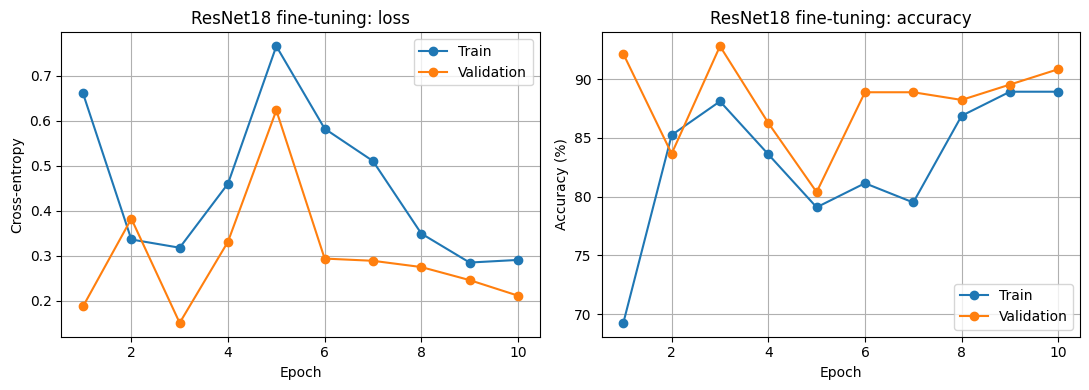

In [14]:
resnet_finetune = get_resnet18_pretrained()
num_features = resnet_finetune.fc.in_features
resnet_finetune.fc = nn.Linear(num_features, len(class_names))
resnet_finetune = resnet_finetune.to(device)

criterion_ft = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(resnet_finetune.parameters(), lr=1e-3, momentum=0.9)
scheduler_ft = optim.lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

resnet_finetune, history_ft, best_acc_ft = train_transfer_model(
    resnet_finetune, criterion_ft, optimizer_ft, scheduler_ft, num_epochs=10
)
plot_transfer_history(history_ft, "ResNet18 fine-tuning")

### 3(b) Feature extraction

Trainable parameters: 1026
Total parameters: 11177538
Epoch 1/10
------------------------------
train loss: 0.7634 acc: 62.70%
val   loss: 0.4668 acc: 76.47%

Epoch 2/10
------------------------------
train loss: 0.4158 acc: 80.74%
val   loss: 0.1503 acc: 94.12%

Epoch 3/10
------------------------------
train loss: 0.4067 acc: 79.51%
val   loss: 0.1782 acc: 94.12%

Epoch 4/10
------------------------------
train loss: 0.6193 acc: 76.64%
val   loss: 0.1625 acc: 96.08%

Epoch 5/10
------------------------------
train loss: 0.3347 acc: 85.66%
val   loss: 0.1954 acc: 92.81%

Epoch 6/10
------------------------------
train loss: 0.4225 acc: 85.25%
val   loss: 0.1845 acc: 92.81%

Epoch 7/10
------------------------------
train loss: 0.4224 acc: 81.15%
val   loss: 0.2299 acc: 91.50%

Epoch 8/10
------------------------------
train loss: 0.3390 acc: 86.48%
val   loss: 0.1614 acc: 95.42%

Epoch 9/10
------------------------------
train loss: 0.2939 acc: 86.89%
val   loss: 0.1848 acc: 94.12%

E

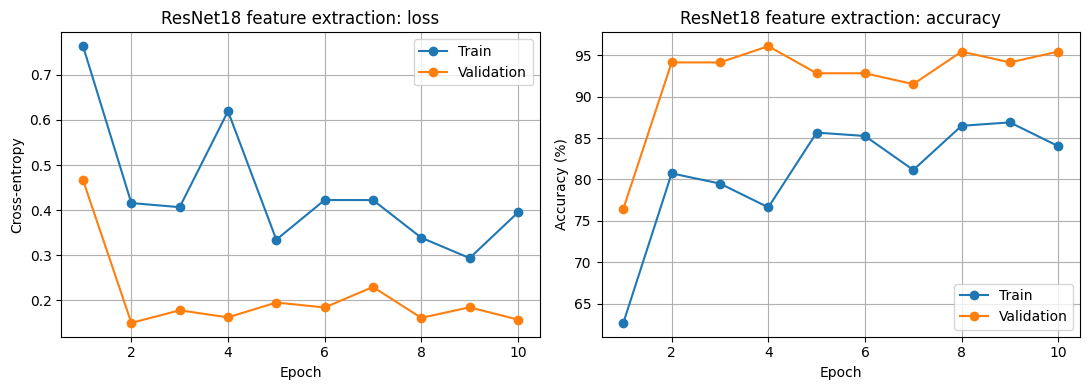

In [15]:
resnet_features = get_resnet18_pretrained()
for param in resnet_features.parameters():
    param.requires_grad = False

num_features = resnet_features.fc.in_features
resnet_features.fc = nn.Linear(num_features, len(class_names))
resnet_features = resnet_features.to(device)

trainable_params = [p for p in resnet_features.parameters() if p.requires_grad]
print("Trainable parameters:", sum(p.numel() for p in trainable_params))
print("Total parameters:", sum(p.numel() for p in resnet_features.parameters()))

criterion_fe = nn.CrossEntropyLoss()
optimizer_fe = optim.SGD(trainable_params, lr=1e-3, momentum=0.9)
scheduler_fe = optim.lr_scheduler.StepLR(optimizer_fe, step_size=7, gamma=0.1)

resnet_features, history_fe, best_acc_fe = train_transfer_model(
    resnet_features, criterion_fe, optimizer_fe, scheduler_fe, num_epochs=10
)
plot_transfer_history(history_fe, "ResNet18 feature extraction")

In [ ]:
comparison_q3 = pd.DataFrame([
    {
        "Method": "Fine-tuning",
        "Best validation accuracy (%)": 100 * best_acc_ft,
        "Trainable parameters": sum(p.numel() for p in resnet_finetune.parameters() if p.requires_grad),
        "Total parameters": sum(p.numel() for p in resnet_finetune.parameters())
    },
    {
        "Method": "Feature extraction",
        "Best validation accuracy (%)": 100 * best_acc_fe,
        "Trainable parameters": sum(p.numel() for p in resnet_features.parameters() if p.requires_grad),
        "Total parameters": sum(p.numel() for p in resnet_features.parameters())
    }
])
comparison_q3.round(2)

,Method,Best validation accuracy (%),Trainable parameters,Total parameters
0,Fine-tuning,92.81,11177538,11177538
1,Feature extraction,96.08,1026,11177538


### Results and discussion

The fine-tuning and feature extraction approaches achieved validation accuracies of **92.81%** and **96.08%**, respectively.

Fine-tuning updates the entire network, while feature extraction trains only the final classifier. The results help compare their classification performance and computational requirements.